# Modulo 1

#### 1-explicar: informe

#### 2-descargar: hecho con Gemini-modelo automático-versión gratuita: Tabla entregable: mensual_df


In [2]:
from fredapi import Fred #descarga los datos
import os #crea carpetas 
from datetime import date #para manipular fechas de calendario
import pandas as pd #para crear y manipular dataframe
from dotenv import load_dotenv
import numpy as np #para convertir vectores
import statsmodels.api as sm #regresiones lineales
#recordar usar pip install fredapi - pip install dotenv - pip install ~, en el terminal/consola 

In [3]:
#autentificacion
load_dotenv("FRED_API_KEY.env")
fred = Fred(api_key=os.getenv("FRED_API_KEY"))

#diccionario con las series y su plazo en años
series_cmt = {
    "DGS1MO": 1 / 12,
    "DGS3MO": 3 / 12,
    "DGS6MO": 6 / 12,
    "DGS1": 1.0,
    "DGS2": 2.0,
    "DGS3": 3.0,
    "DGS5": 5.0,
    "DGS7": 7.0,
    "DGS10": 10.0,
    "DGS20": 20.0,
    "DGS30": 30.0,
}
#descargamos y creamos el dataframe dentro del rango 
raw_df = pd.DataFrame(
    {
        codigo: fred.get_series(
            codigo,
            observation_start="2016-10-01",
            observation_end="2026-09-30",
        )
        for codigo in series_cmt
    }
)
raw_df.index = pd.to_datetime(raw_df.index)
raw_df = raw_df.sort_index()

#limpieza de datos
os.makedirs("data/raw", exist_ok=True) #crea la carpeta data y raw dentro
raw_path = f"data/raw/fred_cmt_diario_{date.today().isoformat()}.csv" # nombre el archivo + ultima fecha de descarga
raw_df.to_csv(raw_path)#guarda la tabla tal como se recibe 

mensual_df = raw_df.dropna(how="all").resample("ME").last() #elimina NA y agrupa por mes y ademas toma ultimo dia
mensual_df.index.name = "fecha_cierre_mes" #nombramos la columna de fecha de cierre IMPORTANTE ACA LO AGREGO COMO INDICE, relevante para graficar


os.makedirs("data/processed", exist_ok=True) #creamos la carpeta
# guarda los datos procesados del apartado anterior en la nueva carpeta
mensual_df.to_csv("data/processed/cmt_mensual_cierre.csv") 

mensual_df.head()

,DGS1MO,DGS3MO,DGS6MO,DGS1,DGS2,DGS3,DGS5,DGS7,DGS10,DGS20,DGS30
fecha_cierre_mes,,,,,,,,,,,
2016-10-31,0.20,0.34,0.51,0.66,0.86,1.00,1.31,1.62,1.84,2.25,2.58
2016-11-30,0.38,0.48,0.62,0.80,1.11,1.40,1.83,2.18,2.37,2.73,3.02
2016-12-31,0.44,0.51,0.62,0.85,1.20,1.47,1.93,2.25,2.45,2.79,3.06
2017-01-31,0.50,0.52,0.64,0.84,1.19,1.46,1.90,2.24,2.45,2.78,3.05
2017-02-28,0.40,0.53,0.69,0.88,1.22,1.49,1.89,2.19,2.36,2.70,2.97


# 3. Elegir plazos
#### Lo típico es elegir:
#### corto 1mes a 1 año
#### mediano 2 años a 7 años
#### largo 10 años a 30 años
#### eligiendo un punto medio, se va a graficar 6 meses, 5 años y 20 años como corto, mediano y largo plazo respectivamente

In [ ]:
import matplotlib.pyplot as plt # paquete para graficar
columna=np.array(list(series_cmt.keys())) # saco los nombres de los bonos/columnas 
cp=columna[2] #6meses
mp=columna[6] #5 años
lp=columna[9] #20 años


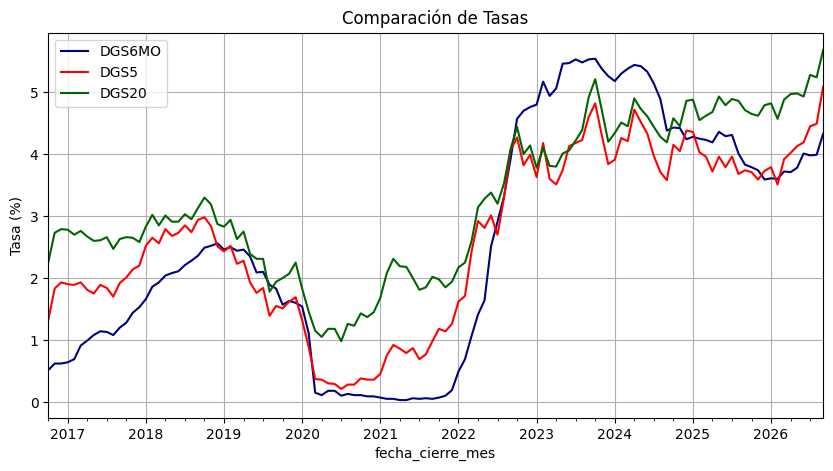

In [5]:
colores=["navy", "red", "darkgreen"]
mensual_df[[cp,mp,lp]].plot(
    figsize=(10, 5),
    title="Comparación de Tasas",
    color=colores)
plt.ylabel("Tasa (%)")
plt.legend(loc="upper left")
plt.grid(True)
plt.show()

# Regresión

#### 4. verficar para tau=1 

In [ ]:
m=np.array(list(series_cmt.values())) #vector de meses en años
tau=1
X_1=(1-np.exp(-m/tau))/(m/tau)
X_2=X_1-np.exp(-m/tau)

In [ ]:
#Me piden reportar scr total de las 120 regresiones (cada mes en la ventana)
scr=0
#además el numero de observaciones utilizadas
nobs=0
for i in range(len(mensual_df)):
    y=mensual_df.iloc[i].values # las tasas en la fecha i, a distintos plazos tantas como instrumentos
    X=np.column_stack((X_1,X_2)) #matriz de regresores
    X=sm.add_constant(X) #como NS tiene intercepto se agrega un vector de 1
    modelo=sm.OLS(y,X).fit() # fit del modelo utilizando OLS
    scr+=modelo.ssr #suma de todos los ssr 
    nobs+=modelo.nobs # numero de observaciones utilizadas basicamente 120*11
scr,nobs    #reportar los valores que me piden



(23.057530642751978, 1320.0)

# 5. ahora buscar tau optimo

In [ ]:
#primero voy a definir las funciones de las variables independientes en función de tau
def X1(tau):
    return (1-np.exp(-m/tau))/(m/tau)
def X2(tau):
    return X1(tau)-np.exp(-m/tau)
#genero un vector de rangos de tau>0
Tau=np.arange(0.1,10,0.01)

In [ ]:
#ahora preciso generar un scr total para cada valor de tau
# lo mismo para nobs, pero a menos que existan missing, debe ser igual para todos
scr_total=[]
nobs_tau=[]
#misma logica pero para cada tau
for j in Tau:
    nobs=0
    scr=0
    for i in range(len(mensual_df)):
        y=mensual_df.iloc[i].values
        X=np.column_stack((X1(j),X2(j)))
        X=sm.add_constant(X)
        modelo=sm.OLS(y,X).fit()
        scr+=modelo.ssr
        nobs+=modelo.nobs
    scr_total.append(scr)
    nobs_tau.append(nobs)

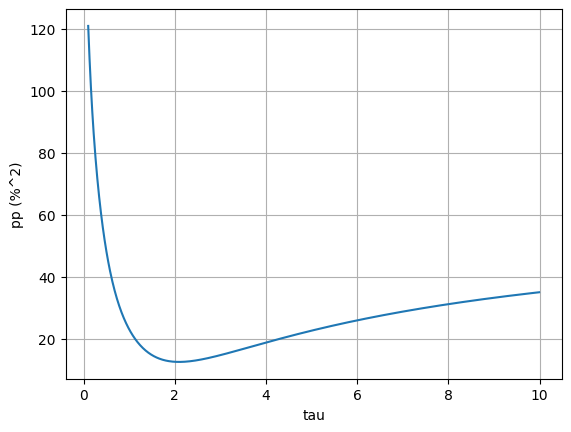

In [25]:
plt.plot(Tau,scr_total)
plt.xlabel("tau")
plt.ylabel("pp (%^2)")
plt.grid(True)
plt.show()

# no es necesario graficar, pero nos da una idea para ver si existen minimos locales o no

In [26]:
# obteniendo los datos para el reporte
indice=np.argmin(scr_total)
tau_optimo=Tau[indice]
scr_min=scr_total[indice]
tau_optimo,scr_min, nobs_tau[indice], sum(nobs_tau)

(2.089999999999999, 12.580904471699776, 1320.0, 1306800.0)

# 6 obtener los betas para el tau optimo

In [ ]:
#misma lógica se repite, para cada fecha existe un set de betas
beta_0=[]
beta_1=[]
beta_2=[]
for i in range(len(mensual_df)):
        y=mensual_df.iloc[i].values
        X=np.column_stack((X1(tau_optimo),X2(tau_optimo)))
        X=sm.add_constant(X)
        modelo=sm.OLS(y,X).fit()
        beta_0.append(modelo.params[0])
        beta_1.append(modelo.params[1])
        beta_2.append(modelo.params[2])

In [ ]:
#creo un dataframe adicional igual al anterior y le agrego los betas para despues graficar y que queden ordenados por fecha
mensual_df_regresores=mensual_df
mensual_df_regresores["beta_0"]=beta_0
mensual_df_regresores["beta_1"]=beta_1
mensual_df_regresores["beta_2"]=beta_2

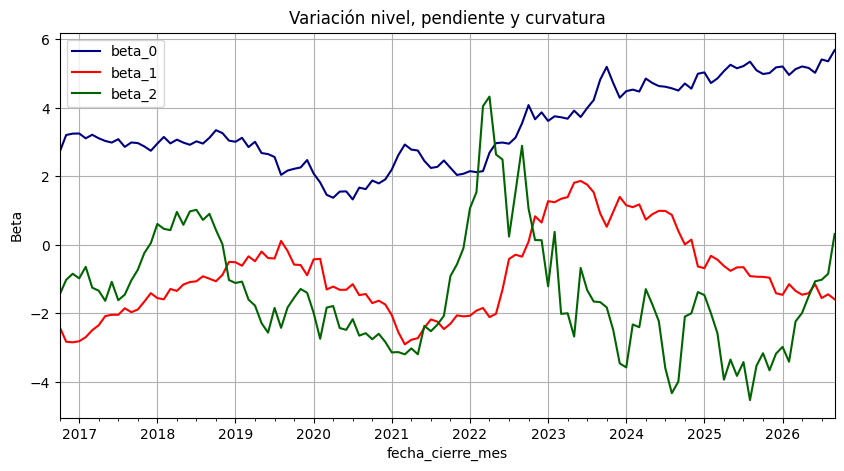

In [27]:
colores=["navy", "red", "darkgreen"]
mensual_df_regresores[["beta_0","beta_1","beta_2"]].plot(
    figsize=(10, 5),
    title="Variación nivel, pendiente y curvatura",
    color=colores)
plt.ylabel("Beta")
plt.legend(loc="upper left")
plt.grid(True)
plt.show()


# 7 descargue la base de datos de feds para  comparar con mis resultados

In [ ]:
feds = pd.read_csv("feds200628.csv", skiprows=9)
feds["Date"] = pd.to_datetime(feds["Date"])

feds = feds[
    (feds["Date"] >= "2016-10-01") &
    (feds["Date"] <= "2026-09-30")
]
#seleccionando la ultima fecha por mes
feds = feds.set_index("Date")
feds_mensual = feds.resample("ME").last()


In [16]:
feds.head()

,BETA0,BETA1,BETA2,BETA3,SVEN1F01,SVEN1F04,SVEN1F09,SVENF01,SVENF02,SVENF03,...,SVENY23,SVENY24,SVENY25,SVENY26,SVENY27,SVENY28,SVENY29,SVENY30,TAU1,TAU2
Date,,,,,,,,,,,,,,,,,,,,,
2016-10-03,4.060191,-3.441743,-2.355574,-4.417859,0.9445,1.7515,2.3100,0.7943,1.0971,1.3949,...,2.2950,2.3340,2.3722,2.4094,2.4459,2.4814,2.5161,2.5499,2.058397,8.880804
2016-10-04,4.272225,-3.690955,-2.213812,-4.566190,0.9935,1.8099,2.4006,0.8336,1.1503,1.4484,...,2.3641,2.4029,2.4410,2.4784,2.5150,2.5508,2.5858,2.6201,2.298547,9.656414
2016-10-05,4.357664,-3.807501,-2.033362,-4.629088,1.0310,1.8477,2.4375,0.8612,1.1932,1.4910,...,2.3979,2.4367,2.4747,2.5120,2.5486,2.5844,2.6196,2.6540,2.421928,9.934867
2016-10-06,4.253072,-3.666345,-2.165721,-4.444276,1.0493,1.8941,2.4622,0.8752,1.2177,1.5290,...,2.4265,2.4651,2.5030,2.5400,2.5762,2.6117,2.6463,2.6801,2.190994,9.309171
2016-10-07,4.068417,-3.528982,-1.745509,-3.859760,1.0447,1.8511,2.4659,0.8731,1.2067,1.4998,...,2.4283,2.4663,2.5034,2.5394,2.5744,2.6085,2.6415,2.6737,2.404160,8.882798


 # Seleccionar cada fecha

In [ ]:
tasa_23=feds_mensual.loc["2023-12-31"] 
tasa_24=feds_mensual.loc["2024-12-31"]
tasa_25=feds_mensual.loc["2025-12-31"]
tasa_26=feds_mensual.loc["2026-09-30"] #septiembre 30 2026

BETA0        2.713314
BETA1        3.043049
BETA2       -0.000048
BETA3        4.638376
SVEN1F01     3.752800
              ...    
SVENY28      4.191500
SVENY29      4.191800
SVENY30      4.191000
TAU1         0.935425
TAU2        17.602144
Name: 2023-12-31 00:00:00, Length: 99, dtype: float64

In [ ]:
SVENPY = [f"SVENPY{i:02d}" for i in range(1, 31)] # me pide solo los svenpy, atajo creado con IA para no escribir el vector entero
svpy_23=tasa_23[SVENPY].values
svpy_24=tasa_24[SVENPY].values
svpy_25=tasa_25[SVENPY].values
svpy_26=tasa_26[SVENPY].values


(array([4.6077, 4.8891, 5.0071, 5.0593, 5.0914, 5.1231, 5.1608, 5.2051,
        5.2542, 5.3057, 5.3574, 5.4072, 5.454 , 5.4967, 5.535 , 5.5685,
        5.5973, 5.6214, 5.6412, 5.6568, 5.6687, 5.6771, 5.6824, 5.6849,
        5.6848, 5.6825, 5.6783, 5.6722, 5.6647, 5.6557]),
 30)

In [98]:
#ahora debo generar con los betas conseguidos
def tasa_estimada(a, beta0, beta1, beta2):
    # a: madurez en años (1 a 30)
    y = beta0 + beta1 * ((1 - np.exp(-a / tau_optimo)) / a / tau_optimo) + beta2 * (((1 - np.exp(-a / tau_optimo)) / a / tau_optimo) - np.exp(-a / tau_optimo))
    return y

In [ ]:
year=np.arange(1,31,1)
regresores=mensual_df_regresores[["beta_0","beta_1","beta_2"]]
#sacando solo los valores que necesito
r_23=regresores.loc["2023-12-31"].values
r_24=regresores.loc["2024-12-31"].values
r_25=regresores.loc["2025-12-31"].values
r_26=regresores.loc["2026-09-30"].values


In [101]:
#luego para cada fecha
svpy_23_estimada=[]
for i in year:
    svpy_23_estimada.append(tasa_estimada(i,r_23[0],r_23[1],r_23[2]))

svpy_24_estimada = []
for i in year:
    svpy_24_estimada.append(tasa_estimada(i, r_24[0], r_24[1], r_24[2]))

svpy_25_estimada = []
for i in year:
    svpy_25_estimada.append(tasa_estimada(i, r_25[0], r_25[1], r_25[2]))

svpy_26_estimada = []
for i in year:
    svpy_26_estimada.append(tasa_estimada(i, r_26[0], r_26[1], r_26[2]))

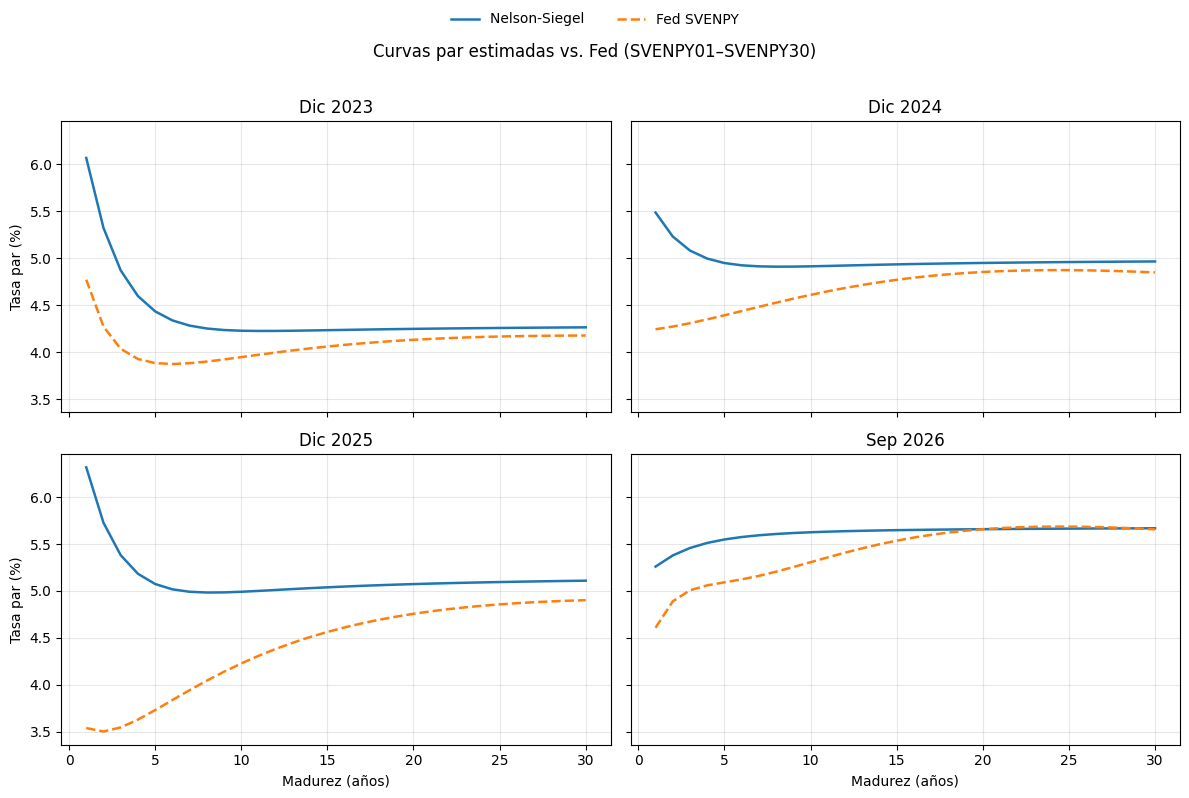

In [111]:
#grafico generado con GEMINI
datos = [
    ("Dic 2023", svpy_23_estimada, tasa_23[SVENPY].to_numpy(dtype=float)),
    ("Dic 2024", svpy_24_estimada, tasa_24[SVENPY].to_numpy(dtype=float)),
    ("Dic 2025", svpy_25_estimada, tasa_25[SVENPY].to_numpy(dtype=float)),
    ("Sep 2026", svpy_26_estimada, tasa_26[SVENPY].to_numpy(dtype=float)),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)

for ax, (titulo, est, fed) in zip(axes.flat, datos):
    ax.plot(year, est, label="Nelson-Siegel ", linewidth=1.8)
    ax.plot(year, fed, linestyle="--", label="Fed SVENPY", linewidth=1.8)
    ax.set_title(titulo)
    ax.grid(True, alpha=0.3)

for ax in axes[1, :]:
    ax.set_xlabel("Madurez (años)")
for ax in axes[:, 0]:
    ax.set_ylabel("Tasa par (%)")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False)
fig.suptitle("Curvas par estimadas vs. Fed (SVENPY01–SVENPY30)", y=0.95)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

# MODULO 2
#### 8.AFP asignada 5mod7=5 -> AFP PROVIDA
#### valor uf https://www.sii.cl/valores_y_fechas/index_valores_y_fechas.html

In [128]:

def parse_cl_num(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().replace(" ", "")
    if "," in s:
        s = s.replace(".", "").replace(",", ".")
    return float(s)


# Ajusta skiprows según dónde empiecen las fechas (en tu captura, las fechas están desde la fila 4)
# Si el separador es tabulación usa sep="\t"; si es coma usa sep=","
df = pd.read_csv(
    "provida.csv",
    sep=";",
    skiprows=3,
    names=["Fecha", "Valor Cuota", "Valor Patrimonio", "UF"],
)

df["Fecha"] = pd.to_datetime(df["Fecha"], format="%d-%m-%Y")
df = df.sort_values("Fecha").set_index("Fecha")

for col in ["Valor Cuota", "Valor Patrimonio", "UF"]:
    df[col] = df[col].apply(parse_cl_num)

fechas_objetivo = pd.to_datetime([
    "2025-12-31",
    "2026-01-31",
    "2026-02-28",
    "2026-03-31",
    "2026-04-30",
    "2026-05-31",
    "2026-06-30",
    "2026-07-31",
    "2026-08-31",
    "2026-09-30",
])

df= df.loc[df.index.isin(fechas_objetivo)].copy()
df = df.sort_index()


In [138]:
df

,Valor Cuota,Valor Patrimonio,UF,r_nom
Fecha,,,,
2025-12-31,62246.99,4.089360e+12,39727.96,NaN
2026-01-31,61848.74,4.034020e+12,39706.07,-0.006398
2026-02-28,63293.18,4.091970e+12,39790.63,0.023354
2026-03-31,62846.27,4.082300e+12,39841.72,-0.007061
2026-04-30,62510.81,4.029060e+12,40120.20,-0.005338
2026-05-31,61677.11,3.933480e+12,40610.69,-0.013337
2026-06-30,62333.93,3.943000e+12,40820.31,0.010649
2026-07-31,60408.41,3.791280e+12,40844.79,-0.030890
2026-08-31,60440.28,3.768640e+12,40873.77,0.000528


In [135]:
df["r_nom"]=df["Valor Cuota"].pct_change()